# Clientes, cohortes y rentabilidad de una tienda online
**Mateo Taylor** · Proyecto de portfolio · Data Analyst

**Pregunta de negocio:** la tienda crece en ventas, pero ¿está creciendo de forma sana? Quiero entender
qué canales traen clientes que **vuelven a comprar**, cuánto vale cada cliente frente a lo que cuesta
conseguirlo y a qué segmentos conviene dirigir cada acción de marketing.

**Datos:** tienda de indumentaria online en Argentina, enero 2024 – diciembre 2025, en dólares.
> ⚠️ **Datos simulados.** El dataset lo generé con `generar_datos.py` siguiendo reglas de negocio
> plausibles (estacionalidad, canales, cupones, devoluciones) y con errores de carga a propósito.
> No representa a ninguna empresa real. El análisis está escrito para funcionar igual con datos reales
> que respeten el mismo esquema.

**Contenido**
1. Carga y calidad de datos
2. KPIs del negocio con SQL
3. Estacionalidad
4. Cohortes de retención
5. Canales: retención, LTV y CAC
6. Segmentación RFM
7. Productos y devoluciones
8. Conclusiones y recomendaciones

In [1]:
import json, sqlite3
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# Estilo de gráficos del proyecto
VERDE, LIMA, GRIS, TINTA = "#4f6b00", "#a6cf1f", "#9aa196", "#1d2219"
PALETA = ["#4f6b00", "#a6cf1f", "#3f9c8f", "#d9a521", "#c75b46", "#7b6fd1"]
plt.rcParams.update({
    "figure.figsize": (10, 4.2), "figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c9cec4", "axes.labelcolor": TINTA, "xtick.color": "#5a6253", "ytick.color": "#5a6253",
    "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlelocation": "left", "axes.titlepad": 12,
    "axes.grid": True, "grid.color": "#e6e9e1", "grid.linewidth": .8, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETA), "font.size": 10.5, "legend.frameon": False,
})
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
DATA = Path("data")

## 1. Carga y calidad de datos
Antes de calcular nada reviso duplicados, valores vacíos, categorías mal escritas y registros que no
corresponden a ventas reales (pedidos cancelados o de prueba).

In [2]:
clientes = pd.read_csv(DATA / "clientes.csv", parse_dates=["fecha_alta"])
pedidos = pd.read_csv(DATA / "pedidos.csv", parse_dates=["fecha"])
items = pd.read_csv(DATA / "items.csv")
marketing = pd.read_csv(DATA / "marketing.csv")

calidad = pd.DataFrame({
    "filas": [len(clientes), len(pedidos), len(items)],
    "duplicados": [clientes.duplicated().sum(), pedidos.duplicated().sum(), items.duplicated().sum()],
    "celdas vacías": [clientes.isna().sum().sum(), pedidos.isna().sum().sum(), items.isna().sum().sum()],
}, index=["clientes", "pedidos", "items"])
calidad

,filas,duplicados,celdas vacías
clientes,6655,0,80
pedidos,10989,65,0
items,20199,0,0


In [3]:
print("Regiones tal como vienen cargadas:")
print(clientes["region"].value_counts(dropna=False).to_string())
print("\nEstados de pedido:", pedidos["estado"].value_counts().to_dict())
print("Pedidos con total en 0:", (pedidos["total_usd"] == 0).sum())

Regiones tal como vienen cargadas:
region
GBA                1935
CABA               1871
Resto del país      809
Córdoba             767
Santa Fe            656
Mendoza             399
NaN                  80
C.A.B.A.             42
Capital Federal      33
caba                 23
cordoba              22
Cordoba              18

Estados de pedido: {'completado': 10656, 'cancelado': 333}
Pedidos con total en 0: 25


Encontré cuatro problemas: **pedidos duplicados**, **regiones escritas de distintas formas**
("caba", "Capital Federal", "Cordoba"…), **regiones vacías** y **pedidos con total en cero**
(pruebas de la plataforma). Los corrijo y dejo registro de cuántas filas toca cada paso.

In [4]:
ALIAS_REGION = {"caba": "CABA", "Capital Federal": "CABA", "C.A.B.A.": "CABA", "Cordoba": "Córdoba", "cordoba": "Córdoba"}

log = {}
n0 = len(pedidos)
pedidos = pedidos.drop_duplicates()
log["duplicados eliminados"] = n0 - len(pedidos)
log["pedidos cancelados (excluidos)"] = int((pedidos["estado"] == "cancelado").sum())
log["pedidos con total 0 (excluidos)"] = int(((pedidos["total_usd"] == 0) & (pedidos["estado"] == "completado")).sum())
ventas = pedidos[(pedidos["estado"] == "completado") & (pedidos["total_usd"] > 0)].copy()

log["regiones normalizadas"] = int(clientes["region"].isin(ALIAS_REGION.keys()).sum())
clientes["region"] = clientes["region"].replace(ALIAS_REGION)
log["regiones vacías → 'Sin dato'"] = int(clientes["region"].isna().sum())
clientes["region"] = clientes["region"].fillna("Sin dato")

items = items[items["pedido_id"].isin(ventas["pedido_id"])]
pd.Series(log, name="filas").to_frame()

,filas
duplicados eliminados,65
pedidos cancelados (excluidos),330
pedidos con total 0 (excluidos),24
regiones normalizadas,138
regiones vacías → 'Sin dato',80


## 2. KPIs del negocio con SQL
Cargo las tablas limpias en una base SQLite en memoria y calculo los indicadores mensuales con SQL,
como lo haría contra la base de datos de la tienda.

In [5]:
con = sqlite3.connect(":memory:")
ventas.assign(fecha=ventas["fecha"].dt.strftime("%Y-%m-%d")).to_sql("ventas", con, index=False)
clientes.assign(fecha_alta=clientes["fecha_alta"].dt.strftime("%Y-%m-%d")).to_sql("clientes", con, index=False)
marketing.to_sql("marketing", con, index=False)

kpis_sql = """
WITH primera AS (
    SELECT cliente_id, MIN(fecha) AS primera_compra FROM ventas GROUP BY cliente_id
)
SELECT
    substr(v.fecha, 1, 7)                                   AS mes,
    ROUND(SUM(v.total_usd), 0)                              AS ingresos_usd,
    COUNT(*)                                                AS pedidos,
    ROUND(AVG(v.total_usd), 2)                              AS ticket_promedio,
    COUNT(DISTINCT v.cliente_id)                            AS clientes_activos,
    COUNT(DISTINCT CASE WHEN substr(p.primera_compra,1,7) = substr(v.fecha,1,7)
                        THEN v.cliente_id END)              AS clientes_nuevos
FROM ventas v
JOIN primera p USING (cliente_id)
GROUP BY mes
ORDER BY mes;
"""
kpis = pd.read_sql(kpis_sql, con)
kpis["clientes_recurrentes"] = kpis["clientes_activos"] - kpis["clientes_nuevos"]
kpis.tail(6)

,mes,ingresos_usd,pedidos,ticket_promedio,clientes_activos,clientes_nuevos,clientes_recurrentes
18,2025-07,"50,574.00",595,85.00,595,344,251
19,2025-08,"36,568.00",460,79.50,460,257,203
20,2025-09,"43,703.00",528,82.77,528,288,240
21,2025-10,"48,612.00",582,83.53,582,333,249
22,2025-11,"68,229.00",861,79.24,861,492,369
23,2025-12,"68,287.00",826,82.67,826,488,338


In [6]:
anual = kpis.assign(anio=kpis["mes"].str[:4]).groupby("anio").agg(
    ingresos_usd=("ingresos_usd", "sum"), pedidos=("pedidos", "sum"), clientes_nuevos=("clientes_nuevos", "sum"))
anual["ticket_promedio"] = anual["ingresos_usd"] / anual["pedidos"]
crec = anual.pct_change().iloc[-1]
print(f"Ingresos 2025 vs 2024: {crec['ingresos_usd']:+.1%} · pedidos {crec['pedidos']:+.1%} · "
      f"clientes nuevos {crec['clientes_nuevos']:+.1%} · ticket {crec['ticket_promedio']:+.1%}")
anual

Ingresos 2025 vs 2024: +70.7% · pedidos +71.5% · clientes nuevos +43.9% · ticket -0.5%


,ingresos_usd,pedidos,clientes_nuevos,ticket_promedio
anio,,,,
2024,"318,442.00",3893,2675,81.80
2025,"543,483.00",6677,3849,81.40


Solo el 38% de los clientes activos de cada mes son recurrentes.


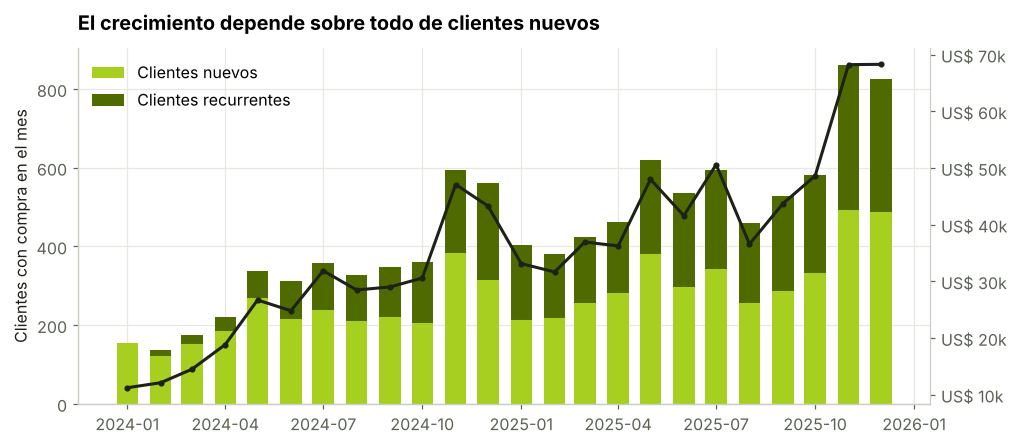

In [7]:
fig, ax = plt.subplots()
x = pd.to_datetime(kpis["mes"])
ax.bar(x, kpis["clientes_nuevos"], width=20, color=LIMA, label="Clientes nuevos")
ax.bar(x, kpis["clientes_recurrentes"], width=20, bottom=kpis["clientes_nuevos"], color=VERDE, label="Clientes recurrentes")
ax.set_title("El crecimiento depende sobre todo de clientes nuevos")
ax.set_ylabel("Clientes con compra en el mes")
ax.legend(loc="upper left")
ax2 = ax.twinx(); ax2.grid(False)
ax2.plot(x, kpis["ingresos_usd"], color=TINTA, lw=2, marker="o", ms=3, label="Ingresos")
ax2.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"US$ {v/1000:.0f}k"))
ax2.spines["right"].set_visible(True)
plt.show()

rec_share = kpis["clientes_recurrentes"].sum() / kpis["clientes_activos"].sum()
print(f"Solo el {rec_share:.0%} de los clientes activos de cada mes son recurrentes.")

## 3. Estacionalidad
El calendario comercial argentino pesa mucho: **Hot Sale** (mayo), **Cyber Monday** (noviembre)
y las fiestas de fin de año.

Tendencia: los ingresos crecen ~6.2% por mes, sin contar la estacionalidad.
Noviembre vende 131% de un mes promedio; febrero, 78%.


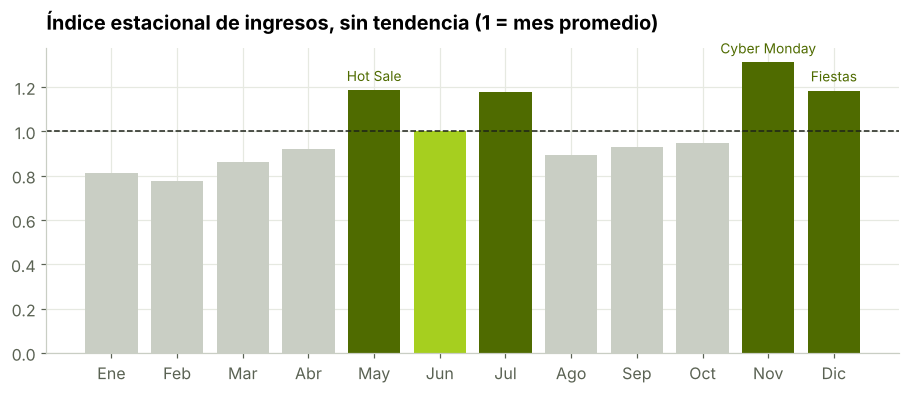

In [8]:
# Saco la tendencia de crecimiento con un ajuste log-lineal; lo que queda es el efecto del mes
kpis["mes_num"] = pd.to_datetime(kpis["mes"]).dt.month
t = np.arange(len(kpis)); logy = np.log(kpis["ingresos_usd"].values)
pend, inter = np.polyfit(t, logy, 1)
resid = pd.Series(logy - (inter + pend * t), index=kpis["mes_num"])
indice = np.exp(resid.groupby(level=0).mean()); indice = indice / indice.mean()
print(f"Tendencia: los ingresos crecen ~{np.exp(pend) - 1:.1%} por mes, sin contar la estacionalidad.")

fig, ax = plt.subplots(figsize=(10, 3.6))
colores = [VERDE if v >= 1.15 else ("#c9cec4" if v < .95 else LIMA) for v in indice]
ax.bar(range(1, 13), indice, color=colores)
ax.axhline(1, color=TINTA, lw=1, ls="--")
ax.set_xticks(range(1, 13), ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"])
ax.set_title("Índice estacional de ingresos, sin tendencia (1 = mes promedio)")
for m, txt in [(5, "Hot Sale"), (11, "Cyber Monday"), (12, "Fiestas")]:
    ax.annotate(txt, (m, indice[m]), xytext=(0, 6), textcoords="offset points", ha="center", fontsize=9, color=VERDE)
plt.show()
print(f"Noviembre vende {indice[11]:.0%} de un mes promedio; febrero, {indice[2]:.0%}.")

## 4. Cohortes de retención
Agrupo a los clientes por el **mes de su primera compra** y mido qué porcentaje vuelve a comprar
en cada mes posterior. Es la mejor forma de ver si la calidad de los clientes mejora o empeora con el tiempo.

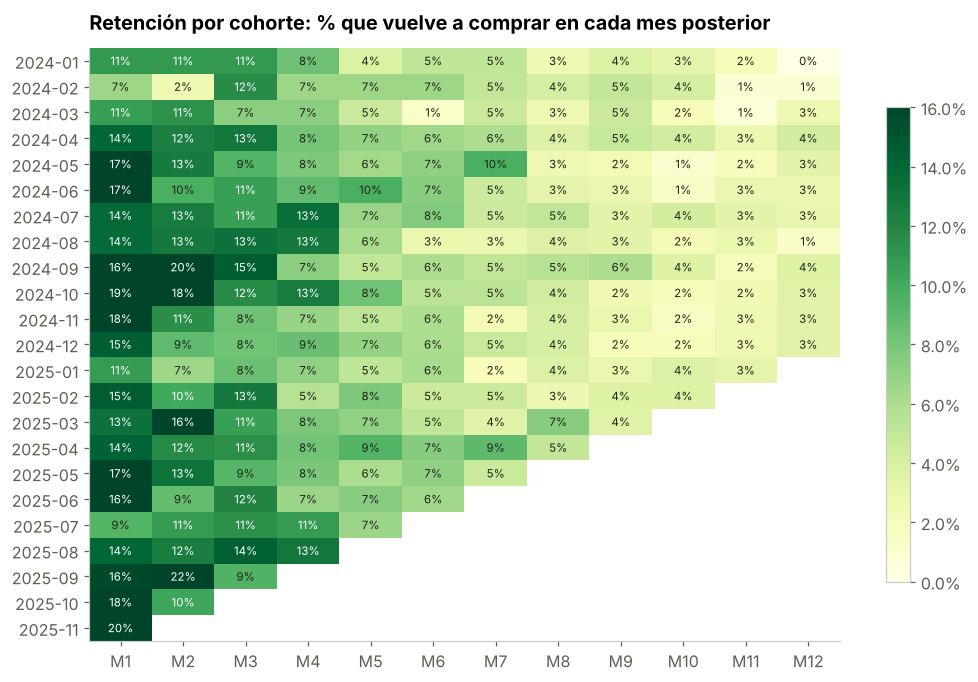

In [9]:
ventas["mes"] = ventas["fecha"].dt.to_period("M")
primera = ventas.groupby("cliente_id")["mes"].min().rename("cohorte")
v = ventas.join(primera, on="cliente_id")
v["mes_n"] = (v["mes"] - v["cohorte"]).apply(lambda d: d.n)

tam = v.groupby("cohorte")["cliente_id"].nunique()
ret = (v.groupby(["cohorte", "mes_n"])["cliente_id"].nunique().unstack(fill_value=0)
       .div(tam, axis=0))
ret = ret.loc[:, 0:12]
# celdas sin datos todavía (meses futuros) quedan vacías
ultimo = ventas["mes"].max()
for c in ret.index:
    for k in ret.columns:
        if c + k > ultimo:
            ret.loc[c, k] = np.nan

fig, ax = plt.subplots(figsize=(11, 7))
m = ret.loc[ret[1].notna(), 1:12]
im = ax.imshow(m.values, cmap="YlGn", aspect="auto", vmin=0, vmax=.16)
ax.set_xticks(range(12), [f"M{k}" for k in m.columns]); ax.set_yticks(range(len(m)), [str(c) for c in m.index])
for i in range(m.shape[0]):
    for j in range(m.shape[1]):
        val = m.values[i, j]
        if not np.isnan(val):
            ax.text(j, i, f"{val:.0%}", ha="center", va="center", fontsize=7.5, color="white" if val > .1 else TINTA)
ax.set_title("Retención por cohorte: % que vuelve a comprar en cada mes posterior")
ax.grid(False); plt.colorbar(im, ax=ax, format=mtick.PercentFormatter(1), shrink=.8)
plt.show()

In [10]:
curva = ret.loc[:, 1:12].mean()
r24 = ret[ret.index.year == 2024].loc[:, 1:6].mean().mean()
r25 = ret[ret.index.year == 2025].loc[:, 1:6].mean().mean()
print(f"Retención promedio M1–M6: cohortes 2024 = {r24:.1%} · cohortes 2025 = {r25:.1%}")
curva.to_frame("retención promedio").T

Retención promedio M1–M6: cohortes 2024 = 9.7% · cohortes 2025 = 9.9%


mes_n,1,2,3,4,5,6,7,8,9,10,11,12
retención promedio,0.15,0.12,0.11,0.09,0.07,0.06,0.05,0.04,0.04,0.03,0.02,0.03


## 5. Canales: retención, LTV y CAC
Para cada canal de adquisición comparo:
- **Recompra a 180 días:** % de clientes que hizo una segunda compra dentro de los 6 meses.
- **LTV a 12 meses:** ingresos promedio por cliente en su primer año.
- **CAC:** inversión del canal dividida por los clientes nuevos que trajo.

Uso solo cohortes con al menos 12 meses de historia (altas de 2024) para que el LTV sea comparable.

In [11]:
alta = v.groupby("cliente_id")["fecha"].min().rename("primera")
v2 = v.join(alta, on="cliente_id").merge(clientes[["cliente_id", "canal_adquisicion"]], on="cliente_id")
v2["dias"] = (v2["fecha"] - v2["primera"]).dt.days
coh24 = v2[v2["primera"] < "2025-01-01"]

por_cliente = coh24.groupby(["cliente_id", "canal_adquisicion"]).agg(
    ltv12=("total_usd", lambda s: s[coh24.loc[s.index, "dias"] <= 365].sum()),
    recompra180=("dias", lambda d: ((d > 0) & (d <= 180)).any())).reset_index()

canal = por_cliente.groupby("canal_adquisicion").agg(clientes=("cliente_id", "count"),
                                                      recompra_180d=("recompra180", "mean"), ltv_12m=("ltv12", "mean"))
inv = marketing[marketing["mes"] < "2025-01"].groupby("canal")["inversion_usd"].sum()
canal["inversion_2024"] = inv
canal["cac"] = canal["inversion_2024"] / canal["clientes"]
canal["ltv_cac"] = canal["ltv_12m"] / canal["cac"]
canal = canal.sort_values("ltv_12m", ascending=False)
canal

,clientes,recompra_180d,ltv_12m,inversion_2024,cac,ltv_cac
canal_adquisicion,,,,,,
Email,226,0.61,235.13,"2,118.38",9.37,25.08
Referidos,286,0.56,200.76,"4,375.90",15.30,13.12
Orgánico,812,0.43,157.02,NaN,NaN,NaN
Google Ads,662,0.35,132.51,"17,897.76",27.04,4.90
Paid Social,689,0.22,97.70,"22,360.00",32.45,3.01


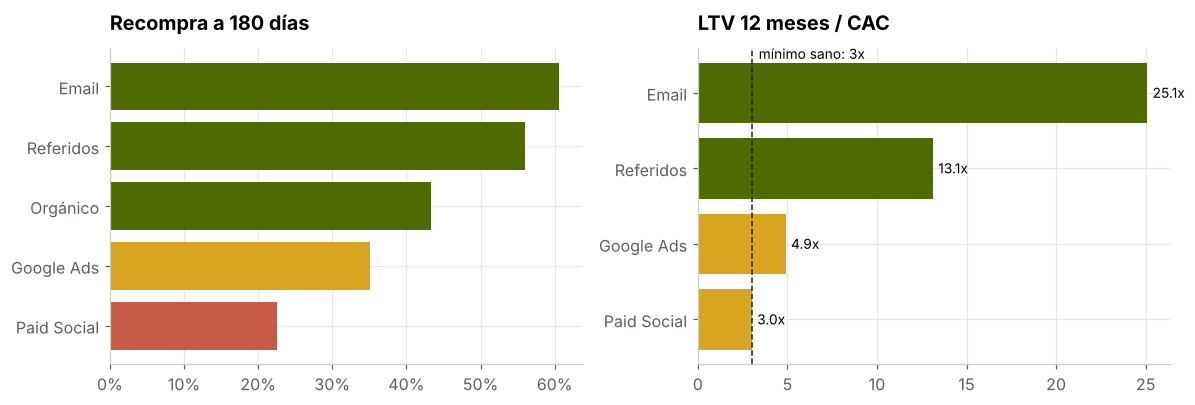

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
c2 = canal.sort_values("recompra_180d")
axes[0].barh(c2.index, c2["recompra_180d"], color=[VERDE if x >= .4 else ("#d9a521" if x >= .3 else "#c75b46") for x in c2["recompra_180d"]])
axes[0].xaxis.set_major_formatter(mtick.PercentFormatter(1)); axes[0].set_title("Recompra a 180 días")
c3 = canal.dropna(subset=["ltv_cac"]).sort_values("ltv_cac")
axes[1].barh(c3.index, c3["ltv_cac"], color=[VERDE if x >= 5 else ("#d9a521" if x >= 3 else "#c75b46") for x in c3["ltv_cac"]])
axes[1].axvline(3, color=TINTA, ls="--", lw=1); axes[1].text(3.4, len(c3) - .55, "mínimo sano: 3x", fontsize=9)
for i, val in enumerate(c3["ltv_cac"]): axes[1].text(val + .3, i, f"{val:.1f}x", va="center", fontsize=9)
axes[1].set_title("LTV 12 meses / CAC")
plt.tight_layout(); plt.show()

**Efecto de los cupones de bienvenida.** Paid Social adquiere muchos clientes con cupón. ¿Esos
clientes vuelven?

In [13]:
primeros = ventas.sort_values("fecha").groupby("cliente_id").first()
cup = primeros.assign(con_cupon=primeros["tipo_descuento"] == "cupón")[["con_cupon"]].join(
    por_cliente.set_index("cliente_id")[["recompra180", "ltv12"]], how="inner")
efecto = cup.groupby("con_cupon").agg(clientes=("recompra180", "size"), recompra_180d=("recompra180", "mean"), ltv_12m=("ltv12", "mean"))
efecto.index = ["Sin cupón", "Con cupón"]
efecto

,clientes,recompra_180d,ltv_12m
Sin cupón,1840,0.43,162.54
Con cupón,835,0.29,112.60


## 6. Segmentación RFM
Puntúo a cada cliente de 1 a 5 según **Recencia** (días desde la última compra), **Frecuencia**
(cantidad de pedidos) y **Monto** (gasto total), al 31/12/2025. Con esas notas armo segmentos accionables.

In [14]:
ref = pd.Timestamp("2025-12-31")
rfm = ventas.groupby("cliente_id").agg(recencia=("fecha", lambda f: (ref - f.max()).days),
                                        frecuencia=("pedido_id", "count"), monto=("total_usd", "sum"))
rfm["R"] = pd.qcut(rfm["recencia"].rank(method="first"), 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm["F"] = pd.cut(rfm["frecuencia"], [0, 1, 2, 3, 5, 999], labels=[1, 2, 3, 4, 5]).astype(int)
rfm["M"] = pd.qcut(rfm["monto"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)

def segmento(r):
    if r.R >= 4 and r.F >= 4: return "Campeones"
    if r.R >= 3 and r.F >= 3: return "Leales"
    if r.R >= 4 and r.F == 1: return "Nuevos"
    if r.R >= 3 and r.F == 2: return "Prometedores"
    if r.R <= 2 and r.F >= 3: return "En riesgo"
    if r.R <= 2: return "Dormidos"
    return "Necesitan atención"

rfm["segmento"] = rfm.apply(segmento, axis=1)
seg = rfm.groupby("segmento").agg(clientes=("monto", "size"), ingresos=("monto", "sum"),
                                   recencia_media=("recencia", "mean"), pedidos_medios=("frecuencia", "mean"))
seg["% clientes"] = seg["clientes"] / seg["clientes"].sum()
seg["% ingresos"] = seg["ingresos"] / seg["ingresos"].sum()
seg = seg.sort_values("ingresos", ascending=False)
seg

,clientes,ingresos,recencia_media,pedidos_medios,% clientes,% ingresos
segmento,,,,,,
Dormidos,2344,"231,811.47",482.72,1.24,0.36,0.27
Prometedores,855,"140,453.94",115.07,2.00,0.13,0.16
Leales,441,"125,006.45",134.24,3.33,0.07,0.15
Nuevos,1542,"115,308.89",62.75,1.00,0.24,0.13
Campeones,245,"108,506.19",57.22,5.00,0.04,0.13
En riesgo,266,"78,277.29",407.50,3.37,0.04,0.09
Necesitan atención,831,"62,561.89",227.08,1.00,0.13,0.07


Campeones + Leales: 11% de los clientes y 27% de los ingresos.
En riesgo: 266 clientes que ya gastaron US$ 78,277.


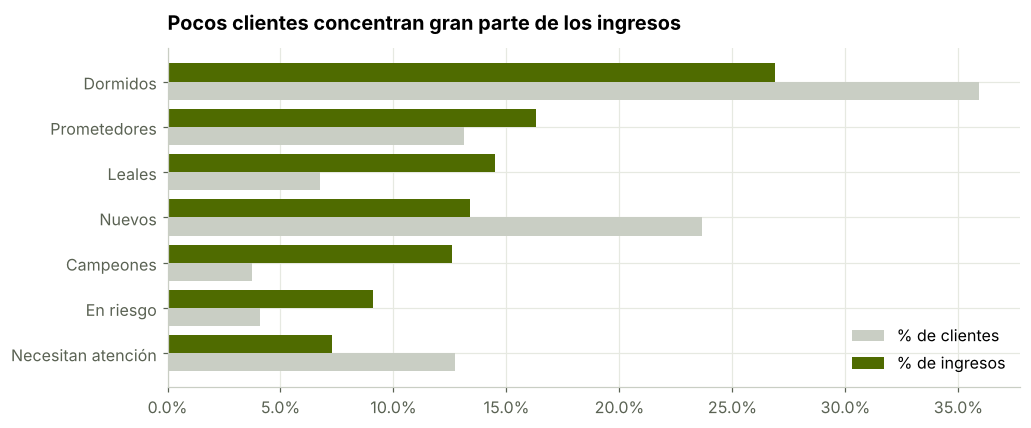

In [15]:
fig, ax = plt.subplots(figsize=(10, 4))
y = np.arange(len(seg))
ax.barh(y + .2, seg["% clientes"], height=.4, color="#c9cec4", label="% de clientes")
ax.barh(y - .2, seg["% ingresos"], height=.4, color=VERDE, label="% de ingresos")
ax.set_yticks(y, seg.index); ax.invert_yaxis()
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_title("Pocos clientes concentran gran parte de los ingresos"); ax.legend(loc="lower right")
plt.show()

top = seg.loc[["Campeones", "Leales"]]
print(f"Campeones + Leales: {top['% clientes'].sum():.0%} de los clientes y {top['% ingresos'].sum():.0%} de los ingresos.")
print(f"En riesgo: {seg.loc['En riesgo', 'clientes']:,} clientes que ya gastaron US$ {seg.loc['En riesgo', 'ingresos']:,.0f}.")

## 7. Productos y devoluciones

In [16]:
items["importe"] = items["cantidad"] * items["precio_unit_usd"]
cat = items.groupby("categoria").agg(unidades=("cantidad", "sum"), importe=("importe", "sum"), tasa_devolucion=("devuelto", "mean"))
cat["% ventas"] = cat["importe"] / cat["importe"].sum()
cat = cat.sort_values("importe", ascending=False)
cat

,unidades,importe,tasa_devolucion,% ventas
categoria,,,,
Zapatillas,2828,"251,680.85",0.11,0.28
Camperas,1767,"175,353.25",0.06,0.19
Pantalones,3573,"159,403.63",0.08,0.18
Buzos,3664,"146,566.35",0.05,0.16
Remeras,6450,"125,522.01",0.04,0.14
Accesorios,3243,"46,629.62",0.02,0.05


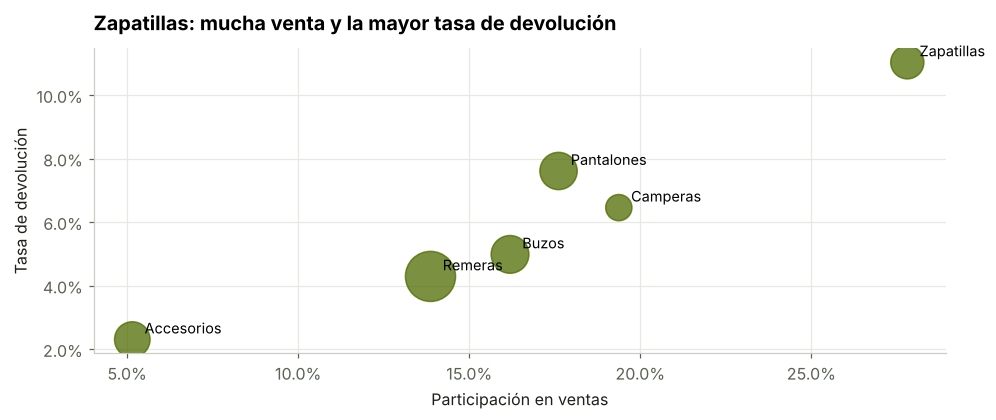

In [17]:
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.scatter(cat["% ventas"], cat["tasa_devolucion"], s=cat["unidades"] / 6, color=VERDE, alpha=.75)
for name, r in cat.iterrows():
    ax.annotate(name, (r["% ventas"], r["tasa_devolucion"]), xytext=(8, 4), textcoords="offset points", fontsize=9.5)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_xlabel("Participación en ventas"); ax.set_ylabel("Tasa de devolución")
ax.set_title("Zapatillas: mucha venta y la mayor tasa de devolución")
plt.show()

## 8. Conclusiones y recomendaciones
**Lo que muestran los datos**
1. **La tienda crece fuerte, pero por volumen, no por fidelidad.** Los ingresos de 2025 subieron un 71 % frente a 2024, impulsados por pedidos (+72 %) y clientes nuevos (+44 %). El ticket promedio se mantuvo plano (US$ 81). Solo el 38 % de los clientes activos de cada mes son recurrentes.
2. **La retención no mejora con el tiempo.** Las cohortes de 2025 retienen prácticamente igual que las de 2024 (≈10 % promedio entre M1 y M6). El crecimiento está "comprando" clientes nuevos, no construyendo una base que vuelva.
3. **El canal que más crece es el que peor retiene.** Paid Social pasó del 26 % al 36 % de los clientes nuevos y del 48 % al 59 % de la inversión. Sin embargo, solo el 22 % de sus clientes vuelve a comprar en 6 meses (contra 61 % de Email y 56 % de Referidos), y su LTV/CAC a 12 meses es de 3,0x, justo en el límite de lo sano.
4. **Los cupones de bienvenida atraen clientes de menor calidad.** Quienes entraron con cupón recompran un 29 % (contra 43 % sin cupón) y gastan un 31 % menos en su primer año.
5. **El valor está concentrado.** Campeones y Leales son el 11 % de los clientes y generan el 27 % de los ingresos. Hay 266 clientes "En riesgo" (compraban seguido y dejaron de hacerlo) que ya gastaron US$ 78.000.
6. **Zapatillas es la categoría más importante y la más problemática:** 28 % de las ventas y 11 % de devoluciones, casi el triple que remeras.

**Recomendaciones**
- **Reasignar presupuesto de Paid Social hacia Referidos y Email:** son los canales con mejor recompra y LTV/CAC (13x y 25x). Por ejemplo, mover un 20 % de la inversión de Paid Social a un programa de referidos y medir el efecto en la retención de las próximas cohortes.
- **Cambiar el cupón de bienvenida por un beneficio en la segunda compra**, para premiar el volver en lugar del primer clic.
- **Campaña de reactivación para "En riesgo"** con un mensaje personalizado según su categoría favorita. Recuperar a una cuarta parte de esos clientes equivale a unos US$ 20.000 de ingresos potenciales, tomando como referencia lo que ya gastaron.
- **Guía de talles y reseñas de calce en Zapatillas** para bajar la tasa de devolución, que impacta directo en el margen.
- **Planificar stock y pauta alrededor de Cyber Monday, Hot Sale y fiestas**, los meses con mayor índice estacional una vez descontada la tendencia.

**Próximos pasos del análisis:** sumar costo de producto y logística para pasar de ingresos a margen, y medir el LTV a 24 meses cuando las cohortes de 2025 maduren.

In [18]:
# Exporto los datos agregados que usa el dashboard web
out = {
    "kpis": {
        "ingresos_2025": float(anual.loc["2025", "ingresos_usd"]), "crec_ingresos": float(crec["ingresos_usd"]),
        "pedidos_2025": int(anual.loc["2025", "pedidos"]), "crec_pedidos": float(crec["pedidos"]),
        "ticket_2025": float(anual.loc["2025", "ticket_promedio"]), "crec_ticket": float(crec["ticket_promedio"]),
        "clientes": int(ventas["cliente_id"].nunique()), "recurrentes_share": float(rec_share),
        "ret_2024": float(r24), "ret_2025": float(r25),
    },
    "mensual": kpis[["mes", "ingresos_usd", "pedidos", "ticket_promedio", "clientes_nuevos", "clientes_recurrentes"]].to_dict("list"),
    "estacional": [float(x) for x in indice.values],
    "cohortes": {"filas": [str(c) for c in ret.index], "valores": [[None if np.isnan(x) else round(float(x), 4) for x in row] for row in ret.loc[:, 1:12].values]},
    "curva": [round(float(x), 4) for x in curva.values],
    "canales": canal.reset_index().rename(columns={"canal_adquisicion": "canal"}).replace({np.nan: None}).to_dict("records"),
    "cupon": efecto.reset_index(names="grupo").to_dict("records"),
    "rfm": seg.reset_index().to_dict("records"),
    "categorias": cat.reset_index().to_dict("records"),
    "limpieza": {k: int(v) for k, v in log.items()},
}
dest = Path("../../ecommerce"); dest.mkdir(parents=True, exist_ok=True)
(dest / "data.json").write_text(json.dumps(out, ensure_ascii=False, default=float))
print("Datos del dashboard exportados:", dest / "data.json")

Datos del dashboard exportados: ../../ecommerce/data.json
